# Deep Learning Assignment 4 — Task 1: Kannada-MNIST Sequential Classification

This notebook implements the required row-by-row image sequence formulation and includes the bonus experiments: **GRU**, **bidirectional recurrent networks**, and **temporal attention pooling**.

## Dataset

The labelled file is split stratified into 70% training, 15% validation, and 15% held-out test. Validation accuracy selects the best model. The test split is evaluated for the required comparison table, but should not be used to make design decisions.

The convergence check uses mean training cross-entropy loss and stops when the absolute difference between successive epoch-average losses is below `1e-4`. `MAX_EPOCHS` is only a safety cap; runs that reach it are clearly marked as not converged. Run all cells from top to bottom and keep outputs visible before submission.

## 1. Imports and reproducibility

In [1]:
import os, glob, copy, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("PyTorch:", torch.__version__)

Device: cuda
PyTorch: 2.11.0+cu130


## 2. Load the designated labelled `train.csv`

In [2]:
# In Colab, upload the labelled train.csv when prompted. In local Jupyter, place it
# in the notebook's working directory or set CSV_PATH to its full path.
CSV_PATH = None  # Example: r"/path/to/train.csv"

if CSV_PATH is not None:
    csv_path = CSV_PATH
elif os.path.exists("/content/train.csv"):
    csv_path = "/content/train.csv"
elif os.path.exists("train.csv"):
    csv_path = "train.csv"
else:
    try:
        from google.colab import files
        uploaded = files.upload()
        candidates = [name for name in uploaded if name.lower().endswith(".csv")]
        exact = [name for name in candidates if os.path.basename(name).lower() == "train.csv"]
        if not exact:
            raise ValueError("Upload the labelled Kannada-MNIST train.csv (not Dig-MNIST.csv or the unlabelled test.csv).")
        csv_path = exact[0]
    except ImportError as exc:
        raise FileNotFoundError("Place the designated labelled train.csv in the working directory or set CSV_PATH.") from exc

if os.path.basename(csv_path).lower() != "train.csv":
    warnings.warn(f"Selected file is named {os.path.basename(csv_path)!r}. Confirm it is the designated labelled Kannada-MNIST train.csv.")

df = pd.read_csv(csv_path)
print("File:", csv_path, "| Shape:", df.shape)
print("Columns preview:", list(df.columns[:8]))
display(df.head())

Saving train.csv to train.csv
File: train.csv | Shape: (60000, 785)
Columns preview: ['label', 'pixel0', 'pixel1', 'pixel2', 'pixel3', 'pixel4', 'pixel5', 'pixel6']


,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


## 3. Validate, normalize, and split

In [3]:
# Expected Kaggle training format: label + 784 pixel columns (an optional ID is tolerated).
label_candidates = [c for c in df.columns if str(c).strip().lower() == "label"]
if len(label_candidates) != 1:
    raise ValueError("Could not find exactly one 'label' column. Use the labelled Kannada-MNIST train.csv.")
label_col = label_candidates[0]
y = df[label_col].to_numpy(dtype=np.int64)
pixel_df = df.drop(columns=[label_col])
id_cols = [c for c in pixel_df.columns if str(c).strip().lower() == "id"]
if id_cols:
    pixel_df = pixel_df.drop(columns=id_cols)

if pixel_df.shape[1] != 784:
    raise ValueError(f"Expected 784 pixel columns after removing label/optional ID; found {pixel_df.shape[1]}. Wrong file or format.")
if not np.isfinite(pixel_df.to_numpy(dtype=np.float32)).all():
    raise ValueError("Pixel data contains NaN or infinite values.")
if not np.isin(np.unique(y), np.arange(10)).all():
    raise ValueError(f"Labels must be digits 0–9; found {np.unique(y)}.")
if set(np.unique(y)) != set(range(10)):
    raise ValueError(f"All ten classes 0–9 must be present; found {np.unique(y)}.")

X = pixel_df.to_numpy(dtype=np.float32)
# Pixel normalization [0,255] -> [0,1], then reshape each image into 28 row timesteps.
if X.min() < 0 or X.max() > 255:
    raise ValueError(f"Expected raw pixel intensities in [0,255], found [{X.min()}, {X.max()}].")
X = (X / 255.0).reshape(-1, 28, 28)

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)
print("X shape (samples, timesteps, features):", X.shape)
print("Classes:", np.unique(y))
print("Normalized pixel range:", float(X.min()), "to", float(X.max()))
for name, xx, yy in [("Train", X_train, y_train), ("Validation", X_val, y_val), ("Test", X_test, y_test)]:
    print(f"{name}: {len(xx)} samples ({len(xx)/len(X):.1%}); class counts = {np.bincount(yy, minlength=10).tolist()}")

X shape (samples, timesteps, features): (60000, 28, 28)
Classes: [0 1 2 3 4 5 6 7 8 9]
Normalized pixel range: 0.0 to 1.0
Train: 42000 samples (70.0%); class counts = [4200, 4200, 4200, 4200, 4200, 4200, 4200, 4200, 4200, 4200]
Validation: 9000 samples (15.0%); class counts = [900, 900, 900, 900, 900, 900, 900, 900, 900, 900]
Test: 9000 samples (15.0%); class counts = [900, 900, 900, 900, 900, 900, 900, 900, 900, 900]


## 4. Create data loaders

In [4]:
BATCH_SIZE = 128
train_dataset = TensorDataset(torch.tensor(X_train, dtype=torch.float32), torch.tensor(y_train, dtype=torch.long))
val_dataset = TensorDataset(torch.tensor(X_val, dtype=torch.float32), torch.tensor(y_val, dtype=torch.long))
test_dataset = TensorDataset(torch.tensor(X_test, dtype=torch.float32), torch.tensor(y_test, dtype=torch.long))
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
train_eval_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=False)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)
print("Batch tensor shape:", next(iter(train_loader))[0].shape, "= (batch, 28 timesteps, 28 features)")

Batch tensor shape: torch.Size([128, 28, 28]) = (batch, 28 timesteps, 28 features)


## 5. Visualize five samples for every digit class (50 total)

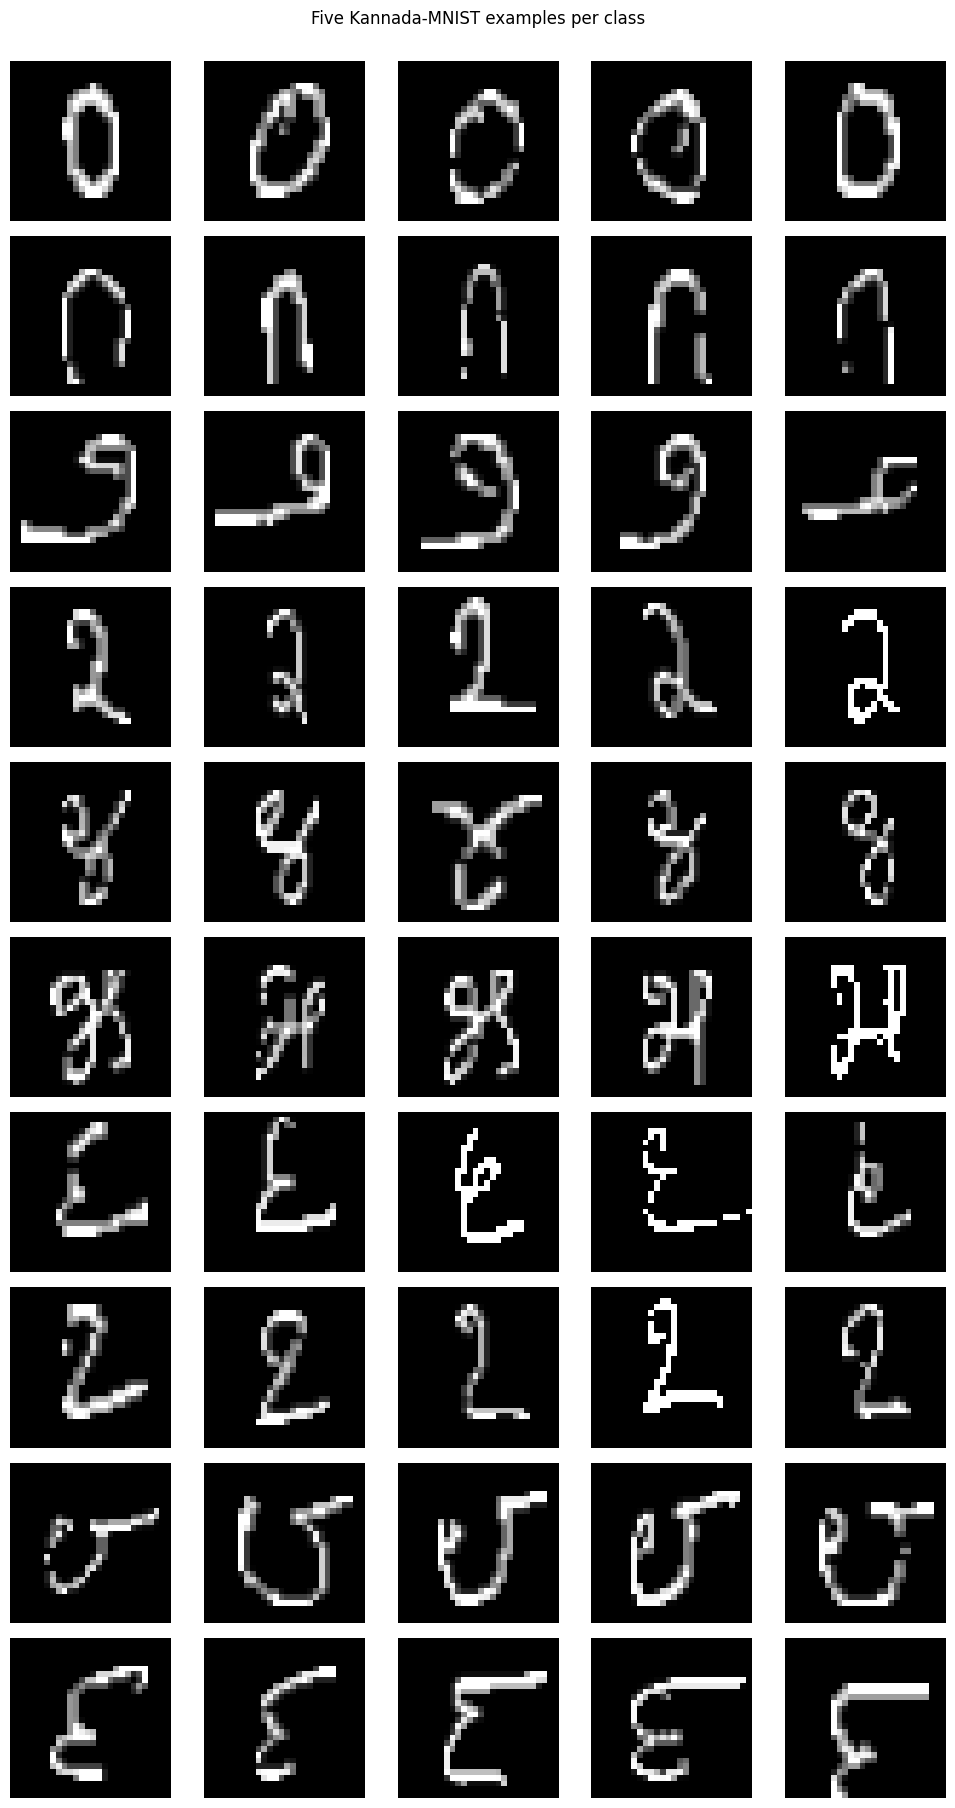

In [5]:
fig, axes = plt.subplots(10, 5, figsize=(10, 18))
for digit in range(10):
    indices = np.where(y_train == digit)[0][:5]
    if len(indices) < 5:
        raise ValueError(f"Class {digit} has fewer than five training samples.")
    for j, idx in enumerate(indices):
        axes[digit, j].imshow(X_train[idx], cmap="gray", vmin=0, vmax=1)
        axes[digit, j].axis("off")
        if j == 0:
            axes[digit, j].set_ylabel(f"Digit {digit}", rotation=90)
plt.suptitle("Five Kannada-MNIST examples per class", y=1.002)
plt.tight_layout()
plt.show()

## 6. Model architectures

- **Vanilla RNN, LSTM, GRU:** recurrent layers process the 28 rows in order.
- **Bidirectional:** each recurrent layer reads the sequence forward and backward; output width doubles.
- **Temporal attention:** learns a score for each timestep, applies softmax over the 28 scores, and computes a weighted sum of timestep representations instead of relying only on the last timestep.

The same class implements all variants. `bidirectional` and `attention` are enabled only in bonus configurations. For stacked bidirectional layers, the next layer receives `2 × hidden_size` features.

In [6]:
class SequenceClassifier(nn.Module):
    def __init__(self, model_type, input_size, hidden_sizes, num_classes,
                 bidirectional=False, attention=False):
        super().__init__()
        recurrent_types = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}
        if model_type not in recurrent_types:
            raise ValueError("model_type must be RNN, LSTM, or GRU")
        if not hidden_sizes or any(int(h) <= 0 for h in hidden_sizes):
            raise ValueError("hidden_sizes must contain positive integers")
        self.model_type = model_type
        self.bidirectional = bool(bidirectional)
        self.attention = bool(attention)
        self.layers = nn.ModuleList()
        current_input_size = input_size
        for hidden_size in hidden_sizes:
            self.layers.append(recurrent_types[model_type](
                input_size=current_input_size,
                hidden_size=int(hidden_size),
                num_layers=1,
                batch_first=True,
                bidirectional=self.bidirectional
            ))
            current_input_size = int(hidden_size) * (2 if self.bidirectional else 1)
        representation_size = current_input_size
        if self.attention:
            self.attention_score = nn.Linear(representation_size, 1)
        self.fc = nn.Linear(representation_size, num_classes)

    def forward(self, x, return_attention=False):
        out = x
        for layer in self.layers:
            out, _ = layer(out)  # out: batch × timesteps × hidden features
        weights = None
        if self.attention:
            scores = self.attention_score(out).squeeze(-1)  # batch × timesteps
            weights = torch.softmax(scores, dim=1)
            representation = torch.sum(out * weights.unsqueeze(-1), dim=1)
        else:
            representation = out[:, -1, :]
        logits = self.fc(representation)
        if return_attention:
            return logits, weights
        return logits

# Shape sanity checks for all model features.
for kwargs in [
    dict(model_type="RNN", hidden_sizes=[32]),
    dict(model_type="LSTM", hidden_sizes=[32, 16], bidirectional=True),
    dict(model_type="GRU", hidden_sizes=[32], attention=True),
    dict(model_type="GRU", hidden_sizes=[32], bidirectional=True, attention=True),
]:
    m = SequenceClassifier(input_size=28, num_classes=10, **kwargs).to(device)
    sample = torch.zeros(4, 28, 28, device=device)
    output = m(sample)
    assert output.shape == (4, 10)
    print(kwargs, "->", tuple(output.shape))

{'model_type': 'RNN', 'hidden_sizes': [32]} -> (4, 10)
{'model_type': 'LSTM', 'hidden_sizes': [32, 16], 'bidirectional': True} -> (4, 10)
{'model_type': 'GRU', 'hidden_sizes': [32], 'attention': True} -> (4, 10)
{'model_type': 'GRU', 'hidden_sizes': [32], 'bidirectional': True, 'attention': True} -> (4, 10)


## 7. Hyperparameter configurations

The first 18 runs are the required baseline comparison: three recurrent cell types × six hidden-layer configurations. Six additional bonus runs explore bidirectionality and/or temporal attention. This is a substantial experiment set; GPU execution is recommended. You can lower `MAX_EPOCHS` for a smoke test, but use the assignment threshold and report any run that reaches the safety cap without converging.

In [7]:
INPUT_SIZE = 28
NUM_CLASSES = 10
LEARNING_RATE = 0.001
CONVERGENCE_THRESHOLD = 1e-4
MAX_EPOCHS = 100  # Safety cap only; convergence criterion is checked every epoch.

HIDDEN_CONFIGS = [[32], [64], [128], [32, 32], [64, 64], [32, 64]]
experiments = [
    {"model_type": model_type, "hidden_sizes": sizes, "bidirectional": False, "attention": False, "group": "Baseline"}
    for model_type in ["RNN", "LSTM", "GRU"] for sizes in HIDDEN_CONFIGS
]
bonus_experiments = [
    {"model_type": "RNN", "hidden_sizes": [64], "bidirectional": True, "attention": False, "group": "Bidirectional"},
    {"model_type": "LSTM", "hidden_sizes": [64], "bidirectional": True, "attention": False, "group": "Bidirectional"},
    {"model_type": "GRU", "hidden_sizes": [64], "bidirectional": True, "attention": False, "group": "Bidirectional"},
    {"model_type": "LSTM", "hidden_sizes": [64], "bidirectional": False, "attention": True, "group": "Temporal attention"},
    {"model_type": "GRU", "hidden_sizes": [64], "bidirectional": False, "attention": True, "group": "Temporal attention"},
    {"model_type": "GRU", "hidden_sizes": [64], "bidirectional": True, "attention": True, "group": "Bidirectional + attention"},
]
experiments.extend(bonus_experiments)

def config_name(config):
    name = f"{config['model_type']}_{'-'.join(map(str, config['hidden_sizes']))}"
    if config.get("bidirectional"): name += "_Bi"
    if config.get("attention"): name += "_Attn"
    return name

print("Baseline configurations:", len([e for e in experiments if e['group'] == 'Baseline']))
print("Bonus configurations:", len(experiments) - 18)
for i, exp in enumerate(experiments, 1):
    print(f"{i:02d}. {config_name(exp)} | {exp['group']}")

Baseline configurations: 18
Bonus configurations: 6
01. RNN_32 | Baseline
02. RNN_64 | Baseline
03. RNN_128 | Baseline
04. RNN_32-32 | Baseline
05. RNN_64-64 | Baseline
06. RNN_32-64 | Baseline
07. LSTM_32 | Baseline
08. LSTM_64 | Baseline
09. LSTM_128 | Baseline
10. LSTM_32-32 | Baseline
11. LSTM_64-64 | Baseline
12. LSTM_32-64 | Baseline
13. GRU_32 | Baseline
14. GRU_64 | Baseline
15. GRU_128 | Baseline
16. GRU_32-32 | Baseline
17. GRU_64-64 | Baseline
18. GRU_32-64 | Baseline
19. RNN_64_Bi | Bidirectional
20. LSTM_64_Bi | Bidirectional
21. GRU_64_Bi | Bidirectional
22. LSTM_64_Attn | Temporal attention
23. GRU_64_Attn | Temporal attention
24. GRU_64_Bi_Attn | Bidirectional + attention


## 8. Training, convergence, evaluation, and gradient-flow logging

The training loss is the mean cross-entropy over all examples in each epoch. The exact requested stopping check is `abs(current_loss - previous_loss) < 1e-4`. A safety cap prevents endless runs; `converged=False` means the threshold was not met before that cap.

For a simple empirical gradient-flow diagnostic, this notebook also logs the norm of the gradients of recurrent parameters during training. This is a diagnostic, not a proof by itself of vanishing/exploding gradients.

In [8]:
def train_one_model(model, train_loader, learning_rate=LEARNING_RATE,
                    threshold=CONVERGENCE_THRESHOLD, max_epochs=MAX_EPOCHS):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    history, gradient_history = [], []
    previous_loss = None
    converged = False

    for epoch in range(1, max_epochs + 1):
        model.train()
        total_loss, total_examples = 0.0, 0
        epoch_grad_norms = []
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad(set_to_none=True)
            logits = model(inputs)
            loss = criterion(logits, labels)
            loss.backward()
            # Aggregate gradient norm for recurrent layer parameters only.
            recurrent_grads = [p.grad.detach().norm(2) for n, p in model.named_parameters()
                               if "layers" in n and p.grad is not None]
            if recurrent_grads:
                epoch_grad_norms.append(torch.stack(recurrent_grads).norm(2).item())
            optimizer.step()
            n = labels.size(0)
            total_loss += loss.item() * n
            total_examples += n

        avg_loss = total_loss / total_examples
        history.append(avg_loss)
        gradient_history.append(float(np.mean(epoch_grad_norms)) if epoch_grad_norms else np.nan)
        if previous_loss is not None and abs(avg_loss - previous_loss) < threshold:
            converged = True
            break
        previous_loss = avg_loss
    return history, gradient_history, converged

@torch.no_grad()
def evaluate_model(model, loader):
    model.eval()
    criterion = nn.CrossEntropyLoss(reduction="sum")
    total_loss = 0.0
    true_labels, predictions = [], []
    for inputs, labels in loader:
        inputs, labels = inputs.to(device), labels.to(device)
        logits = model(inputs)
        total_loss += criterion(logits, labels).item()
        true_labels.extend(labels.cpu().numpy())
        predictions.extend(logits.argmax(dim=1).cpu().numpy())
    return total_loss / len(loader.dataset), accuracy_score(true_labels, predictions), np.asarray(true_labels), np.asarray(predictions)

print("Training/evaluation functions ready.")

Training/evaluation functions ready.


## 9. Run all baseline and bonus experiments

In [9]:
from tqdm.auto import tqdm
import time

# Set RUN_EXPERIMENTS = False to skip training while editing the notebook.
RUN_EXPERIMENTS = True
results, trained_states, histories, gradient_histories = [], {}, {}, {}

if RUN_EXPERIMENTS:
    total_start = time.time()

    progress = tqdm(
        enumerate(experiments, start=1),
        total=len(experiments),
        desc="Training models",
        unit="model"
    )

    for run_number, config in progress:
        run_start = time.time()
        run_name = config_name(config)

        progress.set_postfix(
            current=run_name,
            refresh=True
        )

        random.seed(SEED)
        np.random.seed(SEED)
        torch.manual_seed(SEED)

        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(SEED)

        model = SequenceClassifier(
            config["model_type"],
            INPUT_SIZE,
            config["hidden_sizes"],
            NUM_CLASSES,
            bidirectional=config["bidirectional"],
            attention=config["attention"]
        ).to(device)

        history, grad_history, converged = train_one_model(
            model, train_loader
        )

        histories[run_name] = history
        gradient_histories[run_name] = grad_history

        train_loss, train_acc, _, _ = evaluate_model(
            model, train_eval_loader
        )
        val_loss, val_acc, _, _ = evaluate_model(
            model, val_loader
        )
        test_loss, test_acc, _, _ = evaluate_model(
            model, test_loader
        )

        results.append({
            "run_name": run_name,
            "group": config["group"],
            "architecture": config["model_type"],
            "hidden_sizes": str(config["hidden_sizes"]),
            "num_layers": len(config["hidden_sizes"]),
            "bidirectional": config["bidirectional"],
            "temporal_attention": config["attention"],
            "epochs": len(history),
            "converged": converged,
            "final_training_loss": history[-1],
            "training_accuracy": train_acc,
            "validation_accuracy": val_acc,
            "test_accuracy": test_acc,
            "final_recurrent_gradient_norm": grad_history[-1]
        })

        trained_states[run_name] = {
            "config": copy.deepcopy(config),
            "state_dict": {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }
        }

        elapsed = time.time() - run_start
        total_elapsed = time.time() - total_start
        avg_per_model = total_elapsed / run_number
        remaining = avg_per_model * (len(experiments) - run_number)

        progress.set_postfix({
            "model": run_name,
            "epochs": len(history),
            "test_acc": f"{test_acc:.2%}",
            "converged": converged,
            "last_min": f"{elapsed / 60:.1f}",
            "ETA_min": f"{remaining / 60:.1f}"
        })

        del model

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    progress.close()

    results_df = (
        pd.DataFrame(results)
        .sort_values("validation_accuracy", ascending=False)
        .reset_index(drop=True)
    )

    display(results_df)

    print(f"Total training time: {(time.time() - total_start) / 60:.1f} minutes")

else:
    print("Set RUN_EXPERIMENTS=True and run this cell to train models.")

Training models:   0%|          | 0/24 [00:00<?, ?model/s]

,run_name,group,architecture,hidden_sizes,num_layers,bidirectional,temporal_attention,epochs,converged,final_training_loss,training_accuracy,validation_accuracy,test_accuracy,final_recurrent_gradient_norm
0,LSTM_64-64,Baseline,LSTM,"[64, 64]",2,False,False,54,True,0.001807,0.999905,0.993333,0.994111,0.081451
1,GRU_128,Baseline,GRU,[128],1,False,False,56,True,0.000071,1.000000,0.993000,0.994667,0.002016
2,LSTM_128,Baseline,LSTM,[128],1,False,False,36,True,0.006319,0.998762,0.992333,0.994000,0.175738
3,LSTM_32-64,Baseline,LSTM,"[32, 64]",2,False,False,50,True,0.005475,0.999643,0.992222,0.994111,0.215609
4,GRU_32-64,Baseline,GRU,"[32, 64]",2,False,False,25,True,0.012103,0.996595,0.991000,0.991000,0.295709
5,GRU_64_Bi_Attn,Bidirectional + attention,GRU,[64],1,True,True,35,True,0.005904,0.999119,0.990667,0.991667,0.143522
6,GRU_64-64,Baseline,GRU,"[64, 64]",2,False,False,39,True,0.004500,0.999190,0.989889,0.993000,0.116121
7,LSTM_64,Baseline,LSTM,[64],1,False,False,15,True,0.031601,0.993024,0.989222,0.990111,0.913329
8,GRU_64_Bi,Bidirectional,GRU,[64],1,True,False,31,True,0.008101,0.996452,0.989000,0.990556,0.246838
9,LSTM_64_Bi,Bidirectional,LSTM,[64],1,True,False,38,True,0.008963,0.997952,0.989000,0.990667,0.384566


Total training time: 23.4 minutes


## 10. Training-error plots for every explored configuration

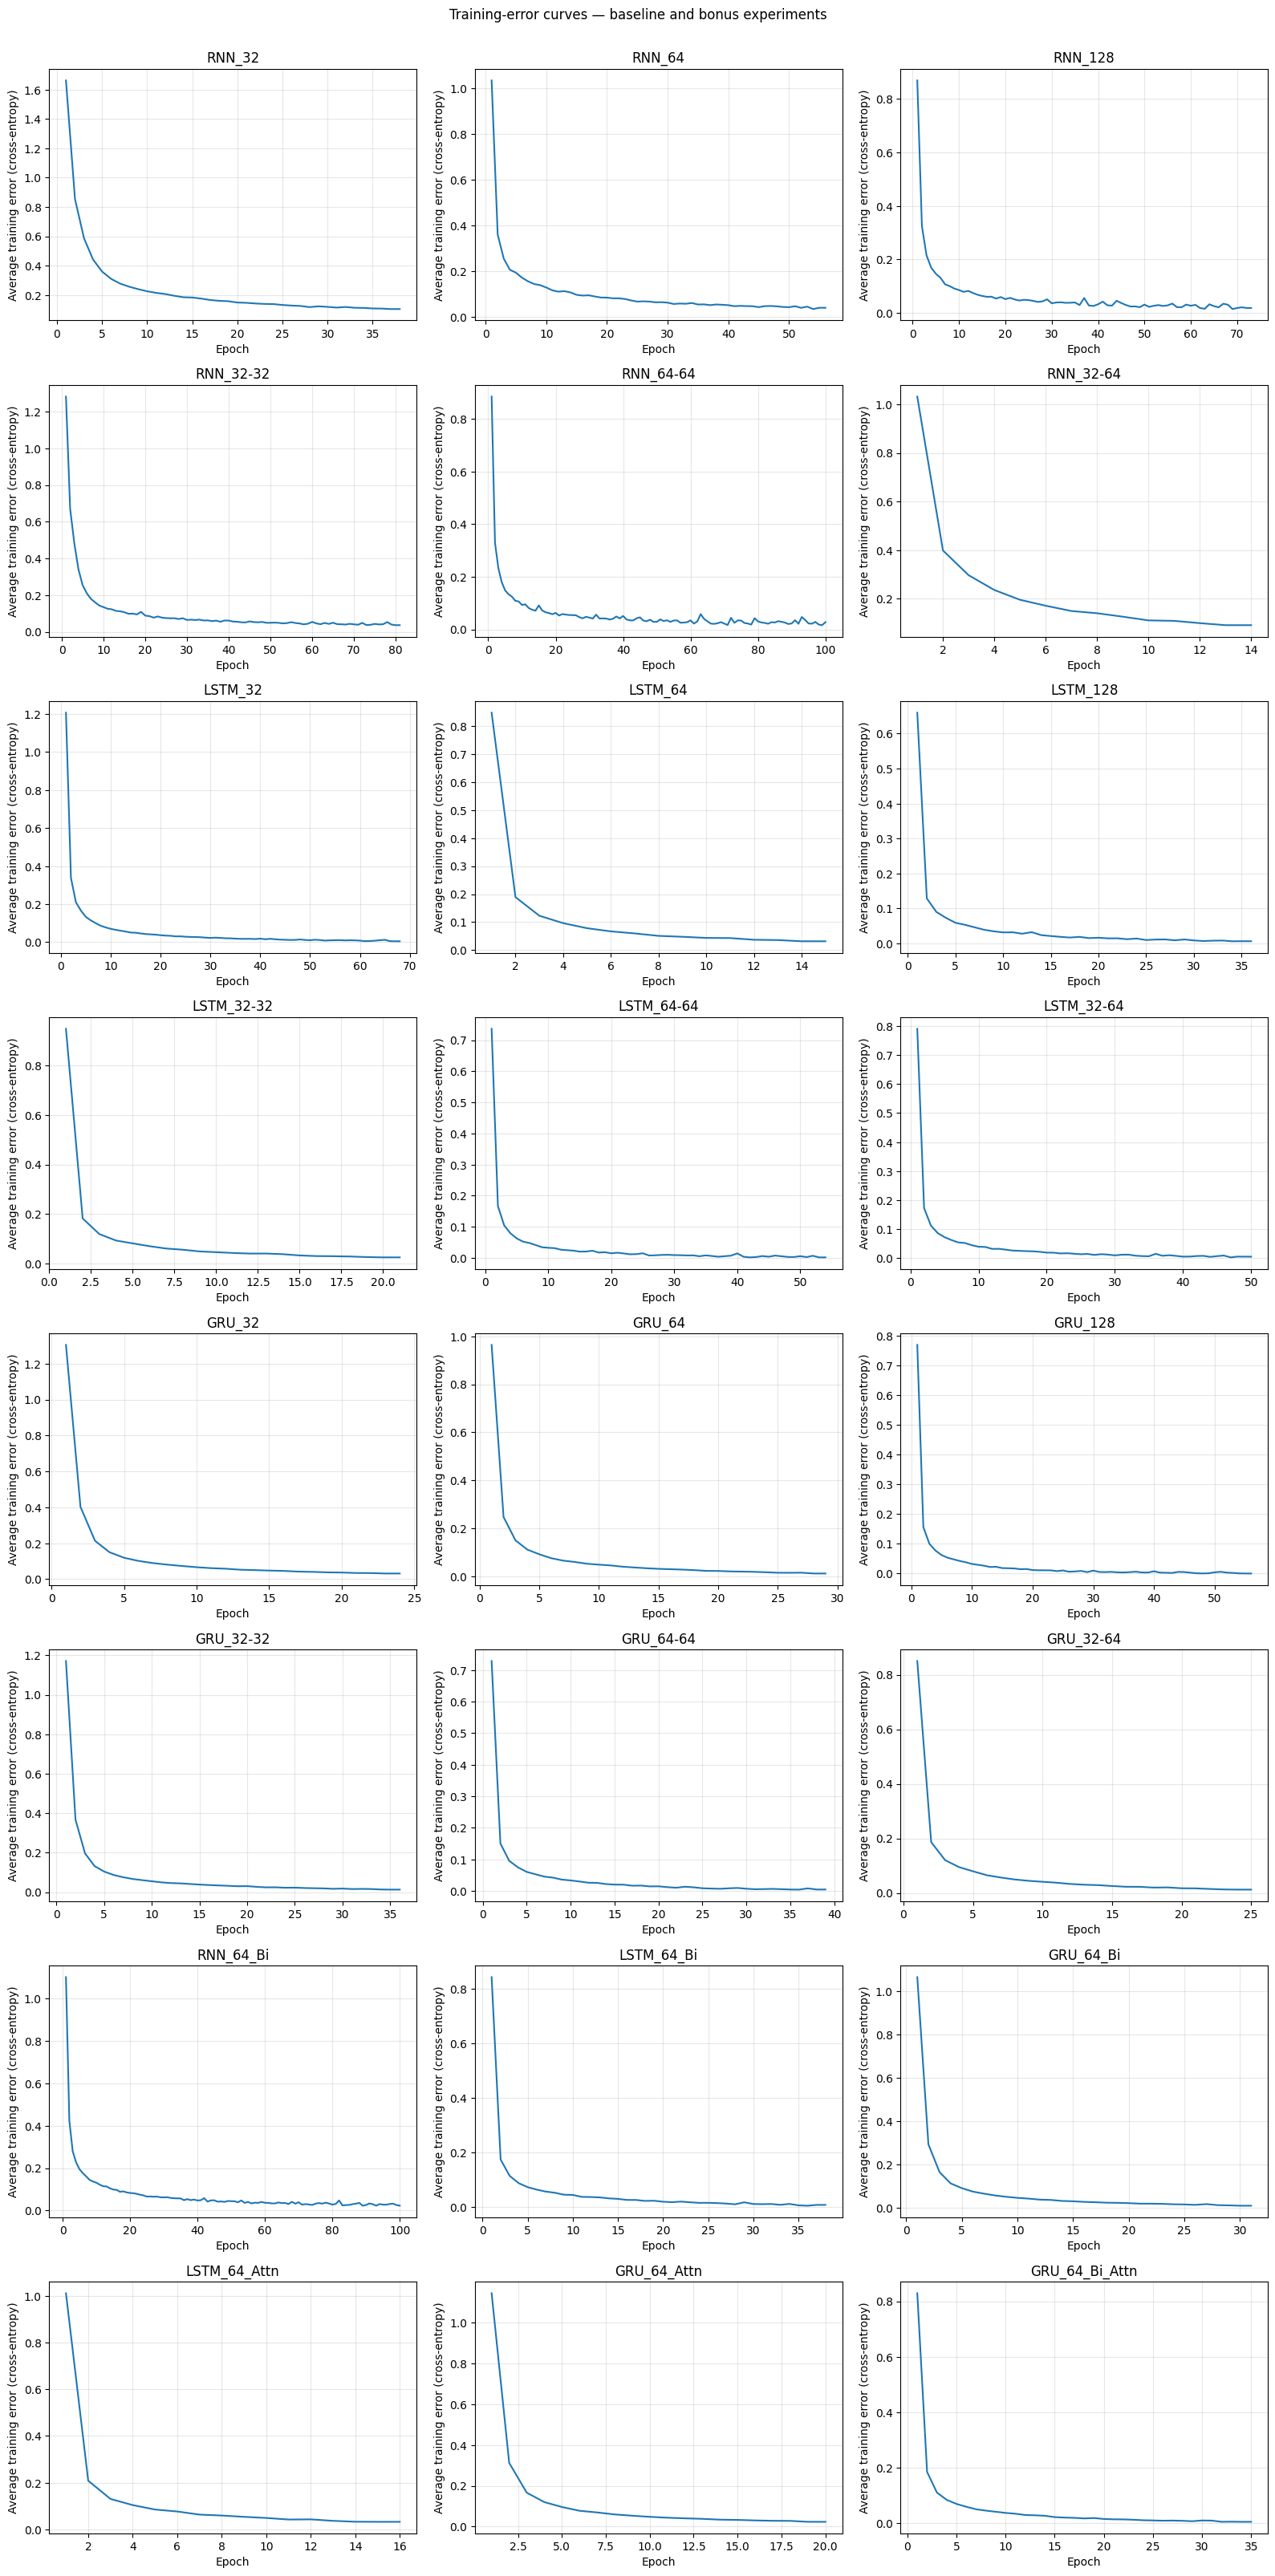

In [10]:
if RUN_EXPERIMENTS:
    ncols = 3
    nrows = int(np.ceil(len(histories) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4 * nrows))
    axes = np.asarray(axes).reshape(-1)
    for ax, (run_name, history) in zip(axes, histories.items()):
        ax.plot(range(1, len(history) + 1), history)
        ax.set_title(run_name)
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Average training error (cross-entropy)")
        ax.grid(True, alpha=0.3)
    for ax in axes[len(histories):]: ax.axis("off")
    plt.suptitle("Training-error curves — baseline and bonus experiments", y=1.002)
    plt.tight_layout(); plt.show()

## 11. Accuracy comparison table

In [11]:
if RUN_EXPERIMENTS:
    comparison_df = results_df[["run_name", "group", "architecture", "hidden_sizes", "num_layers",
        "bidirectional", "temporal_attention", "epochs", "converged", "training_accuracy",
        "validation_accuracy", "test_accuracy"]].copy()
    for col in ["training_accuracy", "validation_accuracy", "test_accuracy"]:
        comparison_df[col] = (comparison_df[col] * 100).round(2)
    display(comparison_df)

,run_name,group,architecture,hidden_sizes,num_layers,bidirectional,temporal_attention,epochs,converged,training_accuracy,validation_accuracy,test_accuracy
0,LSTM_64-64,Baseline,LSTM,"[64, 64]",2,False,False,54,True,99.99,99.33,99.41
1,GRU_128,Baseline,GRU,[128],1,False,False,56,True,100.00,99.30,99.47
2,LSTM_128,Baseline,LSTM,[128],1,False,False,36,True,99.88,99.23,99.40
3,LSTM_32-64,Baseline,LSTM,"[32, 64]",2,False,False,50,True,99.96,99.22,99.41
4,GRU_32-64,Baseline,GRU,"[32, 64]",2,False,False,25,True,99.66,99.10,99.10
5,GRU_64_Bi_Attn,Bidirectional + attention,GRU,[64],1,True,True,35,True,99.91,99.07,99.17
6,GRU_64-64,Baseline,GRU,"[64, 64]",2,False,False,39,True,99.92,98.99,99.30
7,LSTM_64,Baseline,LSTM,[64],1,False,False,15,True,99.30,98.92,99.01
8,GRU_64_Bi,Bidirectional,GRU,[64],1,True,False,31,True,99.65,98.90,99.06
9,LSTM_64_Bi,Bidirectional,LSTM,[64],1,True,False,38,True,99.80,98.90,99.07


## 12. Best configuration and complete held-out test confusion matrix

Best configuration selected by validation accuracy: LSTM_64-64
Config: {'model_type': 'LSTM', 'hidden_sizes': [64, 64], 'bidirectional': False, 'attention': False, 'group': 'Baseline'}
Final training accuracy: 99.9905%
Validation accuracy: 99.3333%
Held-out test accuracy: 99.4111%
Converged: True | Epochs: 54


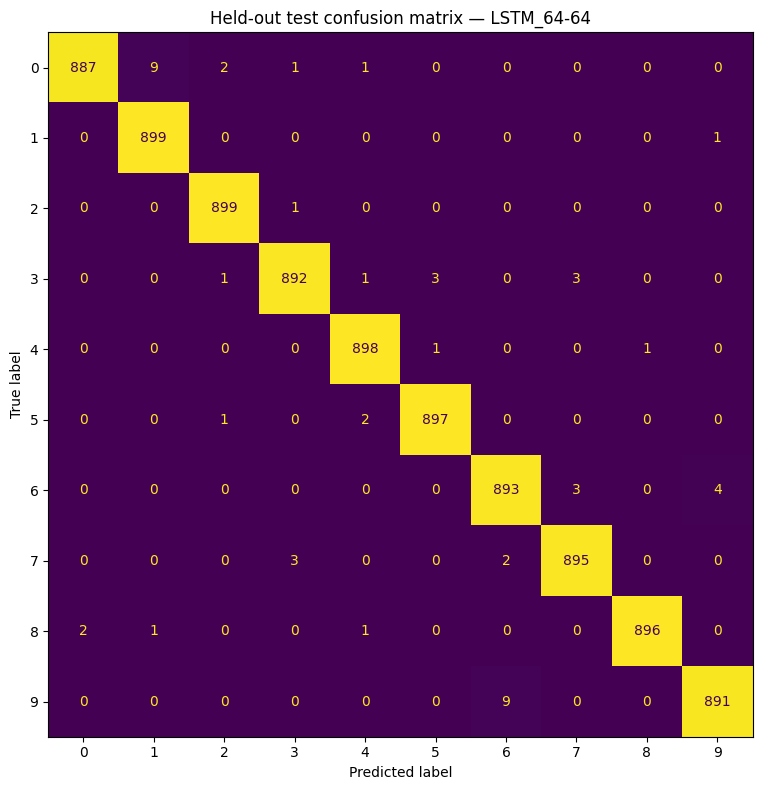

              precision    recall  f1-score   support

           0     0.9978    0.9856    0.9916       900
           1     0.9890    0.9989    0.9939       900
           2     0.9956    0.9989    0.9972       900
           3     0.9944    0.9911    0.9928       900
           4     0.9945    0.9978    0.9961       900
           5     0.9956    0.9967    0.9961       900
           6     0.9878    0.9922    0.9900       900
           7     0.9933    0.9944    0.9939       900
           8     0.9989    0.9956    0.9972       900
           9     0.9944    0.9900    0.9922       900

    accuracy                         0.9941      9000
   macro avg     0.9941    0.9941    0.9941      9000
weighted avg     0.9941    0.9941    0.9941      9000



In [12]:
if RUN_EXPERIMENTS:
    # Select by validation accuracy only.
    best_row = results_df.iloc[0]
    best_name = best_row["run_name"]
    best_saved = trained_states[best_name]
    best_config = best_saved["config"]
    print("Best configuration selected by validation accuracy:", best_name)
    print("Config:", best_config)
    print("Final training accuracy:", f"{best_row['training_accuracy']:.4%}")
    print("Validation accuracy:", f"{best_row['validation_accuracy']:.4%}")
    print("Held-out test accuracy:", f"{best_row['test_accuracy']:.4%}")
    print("Converged:", bool(best_row["converged"]), "| Epochs:", int(best_row["epochs"]))

    best_model = SequenceClassifier(best_config["model_type"], INPUT_SIZE, best_config["hidden_sizes"], NUM_CLASSES,
        bidirectional=best_config["bidirectional"], attention=best_config["attention"]).to(device)
    best_model.load_state_dict(best_saved["state_dict"])
    test_loss, best_test_acc, y_true, y_pred = evaluate_model(best_model, test_loader)
    cm = confusion_matrix(y_true, y_pred, labels=list(range(10)))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=list(range(10)))
    fig, ax = plt.subplots(figsize=(9, 8)); disp.plot(ax=ax, values_format="d", colorbar=False)
    plt.title(f"Held-out test confusion matrix — {best_name}"); plt.tight_layout(); plt.show()
    print(classification_report(y_true, y_pred, labels=list(range(10)), zero_division=0, digits=4))

## 13. Compare baseline architectures and bonus methods

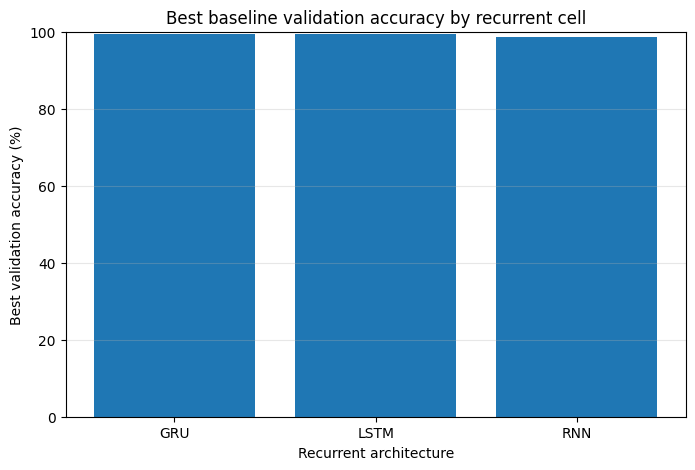

,architecture,hidden_sizes,num_layers,training_accuracy,validation_accuracy,test_accuracy,epochs,converged
0,GRU,[128],1,1.000000,0.993000,0.994667,56,True
1,LSTM,"[64, 64]",2,0.999905,0.993333,0.994111,54,True
2,RNN,[128],1,0.994905,0.985222,0.984667,73,True


,run_name,group,validation_accuracy,test_accuracy,epochs,converged
5,GRU_64_Bi_Attn,Bidirectional + attention,0.990667,0.991667,35,True
8,GRU_64_Bi,Bidirectional,0.989000,0.990556,31,True
9,LSTM_64_Bi,Bidirectional,0.989000,0.990667,38,True
14,LSTM_64_Attn,Temporal attention,0.987444,0.987667,16,True
15,GRU_64_Attn,Temporal attention,0.986444,0.987889,20,True
21,RNN_64_Bi,Bidirectional,0.981333,0.983111,100,False


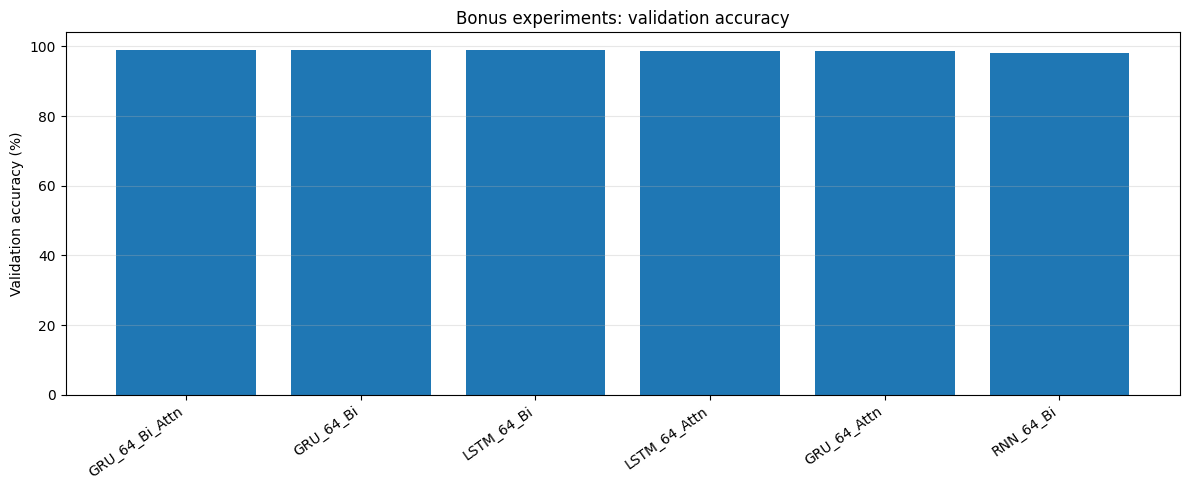

In [13]:
if RUN_EXPERIMENTS:
    baseline_df = results_df[results_df["group"] == "Baseline"]
    best_baseline = baseline_df.sort_values("validation_accuracy", ascending=False).groupby("architecture", as_index=False).first()
    plt.figure(figsize=(8, 5))
    plt.bar(best_baseline["architecture"], best_baseline["validation_accuracy"] * 100)
    plt.ylabel("Best validation accuracy (%)"); plt.xlabel("Recurrent architecture")
    plt.title("Best baseline validation accuracy by recurrent cell")
    plt.ylim(0, 100); plt.grid(axis="y", alpha=0.3); plt.show()
    display(best_baseline[["architecture", "hidden_sizes", "num_layers", "training_accuracy", "validation_accuracy", "test_accuracy", "epochs", "converged"]])

    bonus_df = results_df[results_df["group"] != "Baseline"].sort_values("validation_accuracy", ascending=False)
    display(bonus_df[["run_name", "group", "validation_accuracy", "test_accuracy", "epochs", "converged"]])
    plt.figure(figsize=(12, 5))
    plt.bar(bonus_df["run_name"], bonus_df["validation_accuracy"] * 100)
    plt.ylabel("Validation accuracy (%)"); plt.title("Bonus experiments: validation accuracy")
    plt.xticks(rotation=35, ha="right"); plt.grid(axis="y", alpha=0.3); plt.tight_layout(); plt.show()

## 14. Gradient-flow diagnostic plots

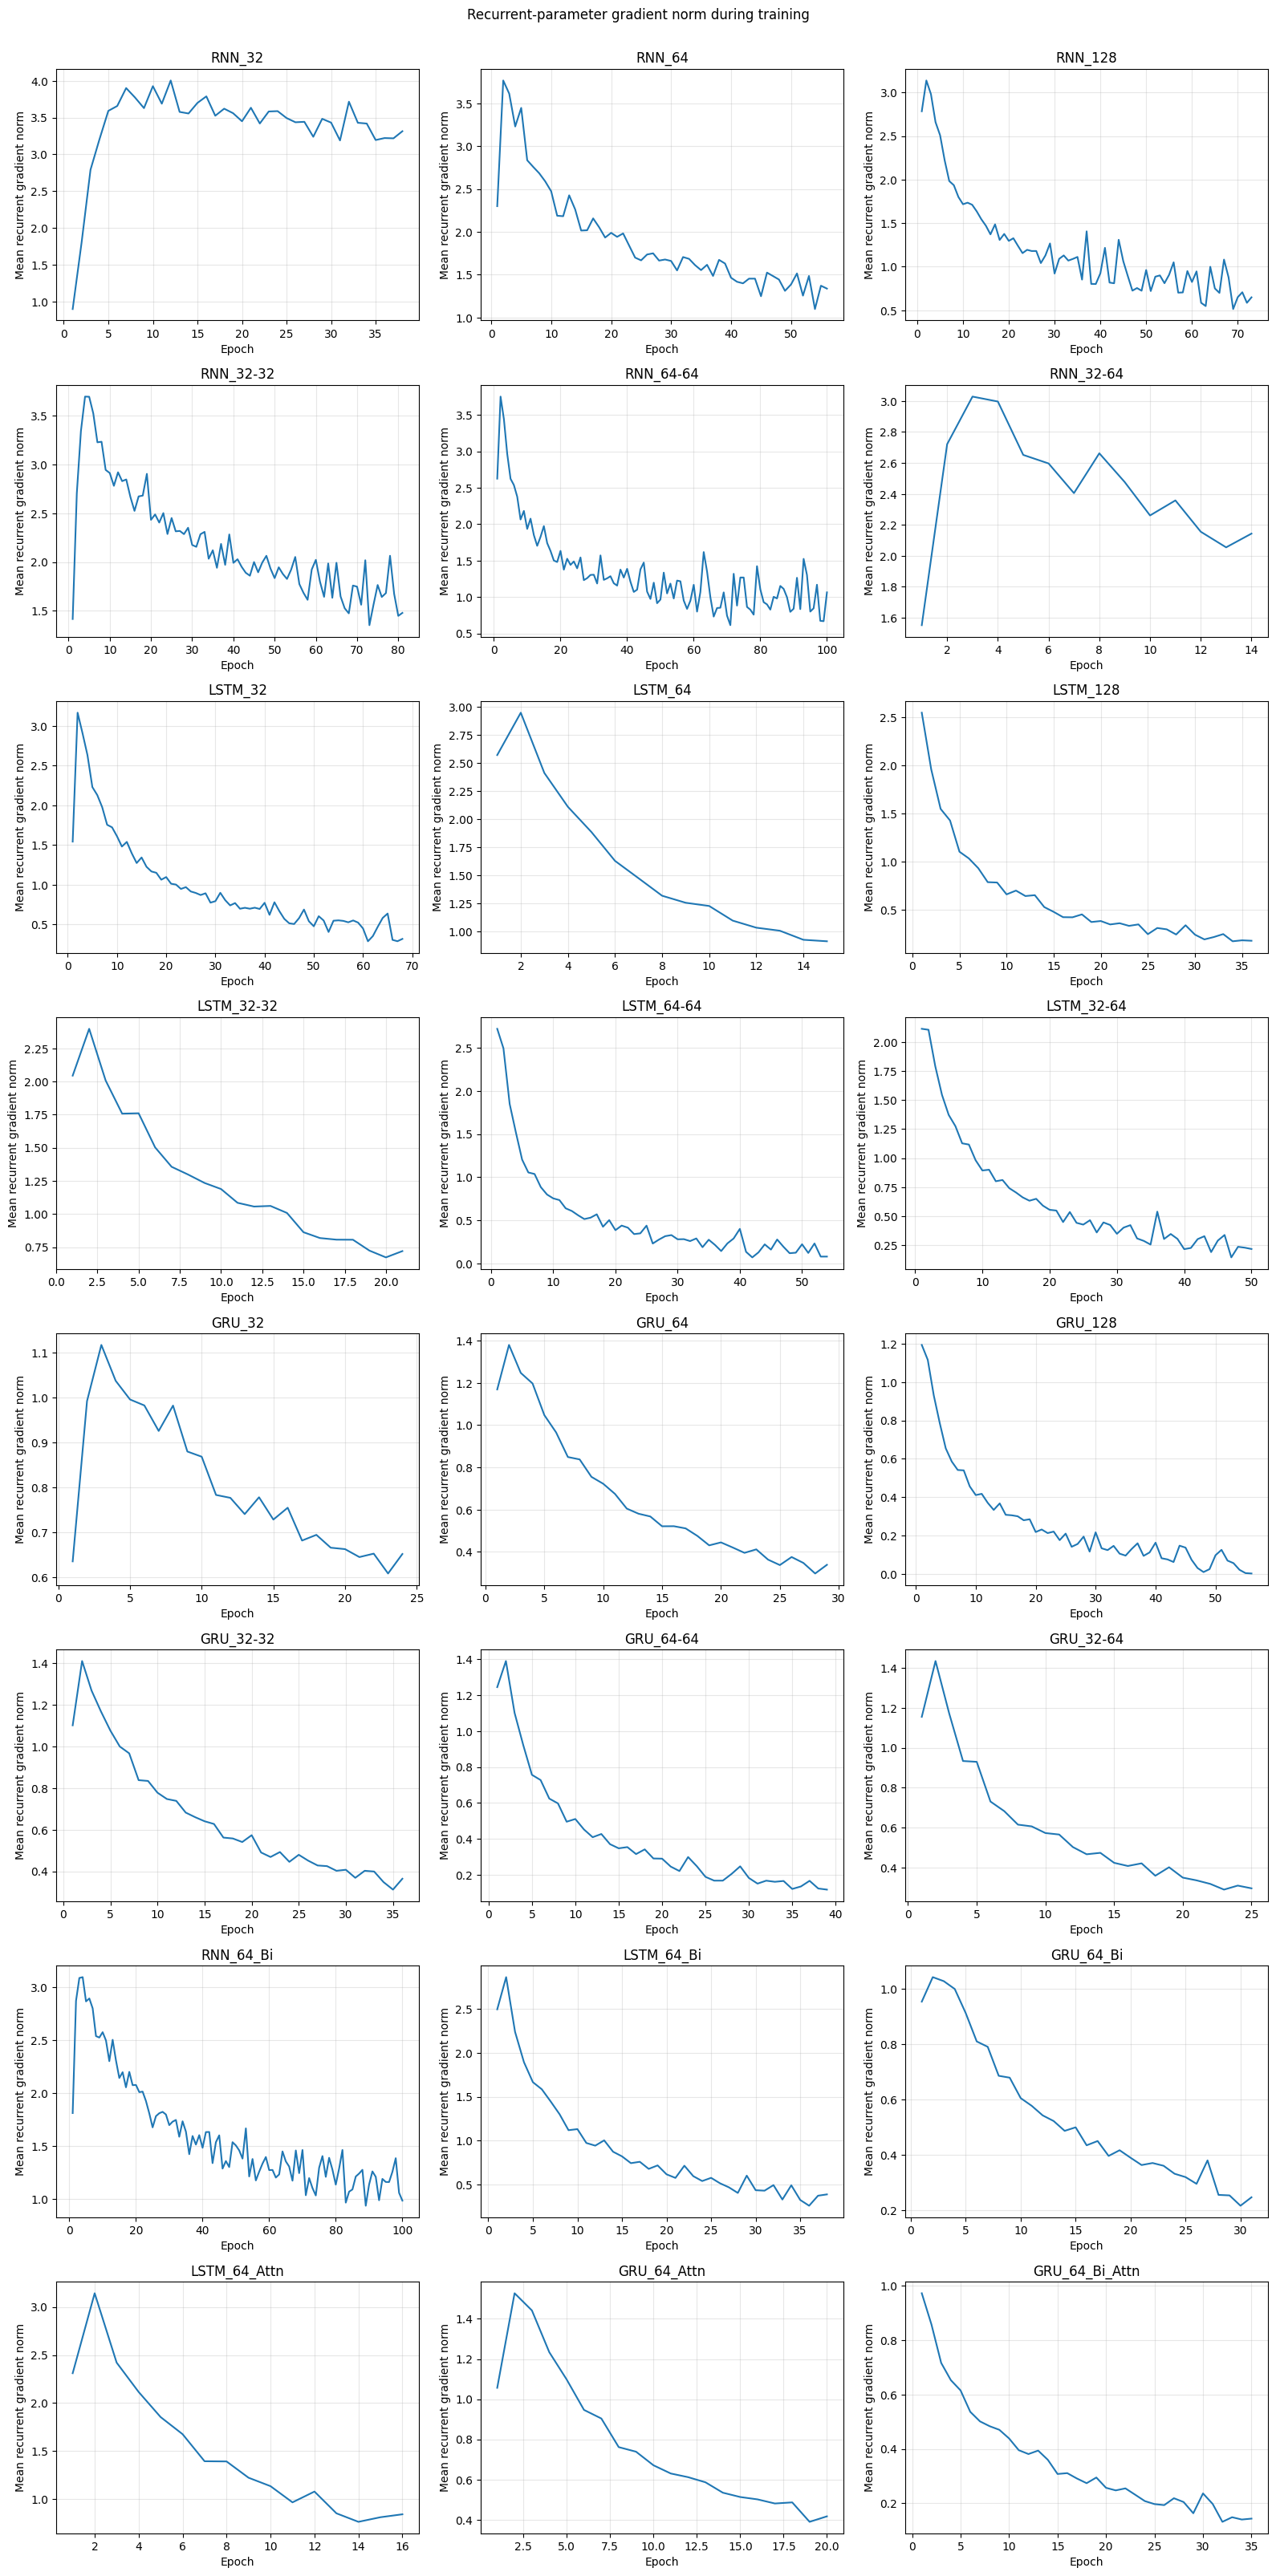

Interpretation: inspect relative scales and whether norms approach zero or become unusually large. Gradient norms alone do not establish causality; discuss them alongside loss curves and model results.


In [14]:
if RUN_EXPERIMENTS:
    ncols = 3; nrows = int(np.ceil(len(gradient_histories) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4 * nrows)); axes = np.asarray(axes).reshape(-1)
    for ax, (run_name, values) in zip(axes, gradient_histories.items()):
        ax.plot(range(1, len(values) + 1), values)
        ax.set_title(run_name); ax.set_xlabel("Epoch"); ax.set_ylabel("Mean recurrent gradient norm")
        ax.grid(True, alpha=0.3)
    for ax in axes[len(gradient_histories):]: ax.axis("off")
    plt.suptitle("Recurrent-parameter gradient norm during training", y=1.002)
    plt.tight_layout(); plt.show()
    print("Interpretation: inspect relative scales and whether norms approach zero or become unusually large. Gradient norms alone do not establish causality; discuss them alongside loss curves and model results.")

## 15. Temporal attention visualization (best attention model)

This visualizes the learned attention weight over the 28 row timesteps for one test example. It is available only if at least one attention configuration was trained.

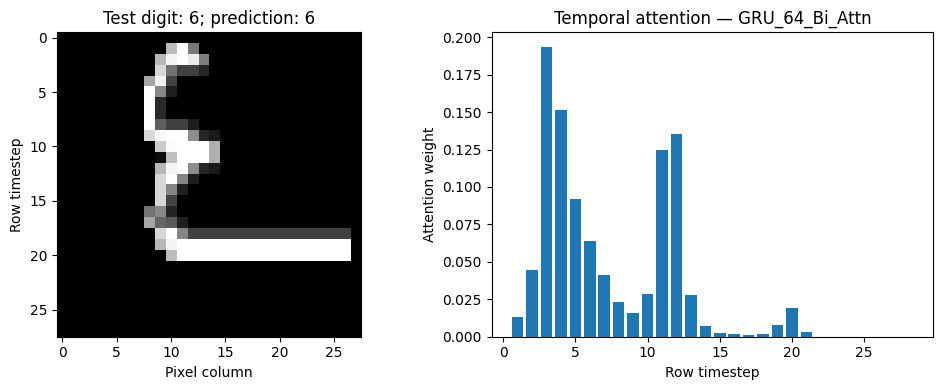

In [15]:
if RUN_EXPERIMENTS:
    attention_rows = results_df[results_df["temporal_attention"] == True]
    if len(attention_rows):
        attn_row = attention_rows.iloc[0]  # best attention model by validation accuracy
        attn_name = attn_row["run_name"]
        attn_config = trained_states[attn_name]["config"]
        attn_model = SequenceClassifier(attn_config["model_type"], INPUT_SIZE, attn_config["hidden_sizes"], NUM_CLASSES,
            bidirectional=attn_config["bidirectional"], attention=True).to(device)
        attn_model.load_state_dict(trained_states[attn_name]["state_dict"])
        attn_model.eval()
        sample_x = X_test[0]
        with torch.no_grad():
            logits, weights = attn_model(torch.tensor(sample_x[None], dtype=torch.float32, device=device), return_attention=True)
            predicted = int(logits.argmax(1).item())
            attention_weights = weights.squeeze(0).cpu().numpy()
        fig, axes = plt.subplots(1, 2, figsize=(10, 4))
        axes[0].imshow(sample_x, cmap="gray", vmin=0, vmax=1); axes[0].set_title(f"Test digit: {int(y_test[0])}; prediction: {predicted}")
        axes[0].set_xlabel("Pixel column"); axes[0].set_ylabel("Row timestep")
        axes[1].bar(np.arange(1, 29), attention_weights); axes[1].set_xlabel("Row timestep")
        axes[1].set_ylabel("Attention weight"); axes[1].set_title(f"Temporal attention — {attn_name}")
        plt.tight_layout(); plt.show()
    else:
        print("No attention configuration was trained.")

## 16. Export result tables and histories

In [16]:
if RUN_EXPERIMENTS:
    results_df.to_csv("task1_all_results.csv", index=False)
    comparison_df.to_csv("task1_comparison_table.csv", index=False)
    history_rows = []
    for run_name, history in histories.items():
        for epoch, loss in enumerate(history, start=1):
            history_rows.append({"run_name": run_name, "epoch": epoch,
                "average_training_error": loss,
                "recurrent_gradient_norm": gradient_histories[run_name][epoch - 1]})
    pd.DataFrame(history_rows).to_csv("task1_training_histories.csv", index=False)
    print("Saved: task1_all_results.csv, task1_comparison_table.csv, task1_training_histories.csv")

Saved: task1_all_results.csv, task1_comparison_table.csv, task1_training_histories.csv
